In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

import time
import os
import glob

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
files = {}

for name in ["X_train", "X_test", "y_train", "y_test"]:
    matches = glob.glob(
        f"/kaggle/input/**/{name}.csv",
        recursive=True
    )

    if not matches:
        raise FileNotFoundError(f"{name}.csv not found!")

    files[name] = matches[0]

X_train = pd.read_csv(files["X_train"]).values
X_test = pd.read_csv(files["X_test"]).values

y_train = pd.read_csv(files["y_train"]).values.ravel()
y_test = pd.read_csv(files["y_test"]).values.ravel()

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Data loaded successfully!
X_train: (8929, 50)
X_test: (2233, 50)
y_train: (8929,)
y_test: (2233,)


In [3]:
def adam(
    X, y,
    learning_rate=0.001,
    epochs=100,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8
):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    m_w = np.zeros(n_features)
    v_w = np.zeros(n_features)

    m_b = 0.0
    v_b = 0.0

    loss_history = []

    for epoch in range(1, epochs + 1):

        z = np.dot(X, weights) + bias
        y_pred = sigmoid(z)

        dw = np.dot(X.T, (y_pred - y)) / n_samples
        db = np.mean(y_pred - y)

        m_w = beta1 * m_w + (1 - beta1) * dw
        v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)

        m_b = beta1 * m_b + (1 - beta1) * db
        v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

        m_w_corrected = m_w / (1 - beta1 ** epoch)
        v_w_corrected = v_w / (1 - beta2 ** epoch)

        m_b_corrected = m_b / (1 - beta1 ** epoch)
        v_b_corrected = v_b / (1 - beta2 ** epoch)

        weights -= learning_rate * m_w_corrected / (
            np.sqrt(v_w_corrected) + epsilon
        )

        bias -= learning_rate * m_b_corrected / (
            np.sqrt(v_b_corrected) + epsilon
        )

        loss = compute_loss(
            y,
            sigmoid(np.dot(X, weights) + bias)
        )

        loss_history.append(loss)

    return weights, bias, loss_history


print("Adam optimizer created successfully!")

Adam optimizer created successfully!


In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


print("Sigmoid and Loss functions created successfully!")

Sigmoid and Loss functions created successfully!


In [5]:
start_time = time.time()

weights_adam, bias_adam, loss_history_adam = adam(
    X_train,
    y_train,
    learning_rate=0.001,
    epochs=100
)

training_time_adam = time.time() - start_time

print("Adam Training Completed!")
print("Final Training Loss:", loss_history_adam[-1])
print("Training Time:", round(training_time_adam, 4))

Adam Training Completed!
Final Training Loss: 0.6327429492451072
Training Time: 0.1188


In [6]:
def predict(X, weights, bias, threshold=0.5):
    probabilities = sigmoid(np.dot(X, weights) + bias)
    return (probabilities >= threshold).astype(int)


y_pred_adam = predict(
    X_test,
    weights_adam,
    bias_adam
)

print("Adam Predictions generated successfully!")

Adam Predictions generated successfully!


In [7]:
accuracy_adam = accuracy_score(y_test, y_pred_adam)
precision_adam = precision_score(y_test, y_pred_adam)
recall_adam = recall_score(y_test, y_pred_adam)
f1_adam = f1_score(y_test, y_pred_adam)

print("Adam Optimizer Results")
print("------------------------------")
print("Accuracy:", round(accuracy_adam, 4))
print("Precision:", round(precision_adam, 4))
print("Recall:", round(recall_adam, 4))
print("F1-Score:", round(f1_adam, 4))
print("Training Time:", round(training_time_adam, 4))

Adam Optimizer Results
------------------------------
Accuracy: 0.6753
Precision: 0.697
Recall: 0.5567
F1-Score: 0.619
Training Time: 0.1188


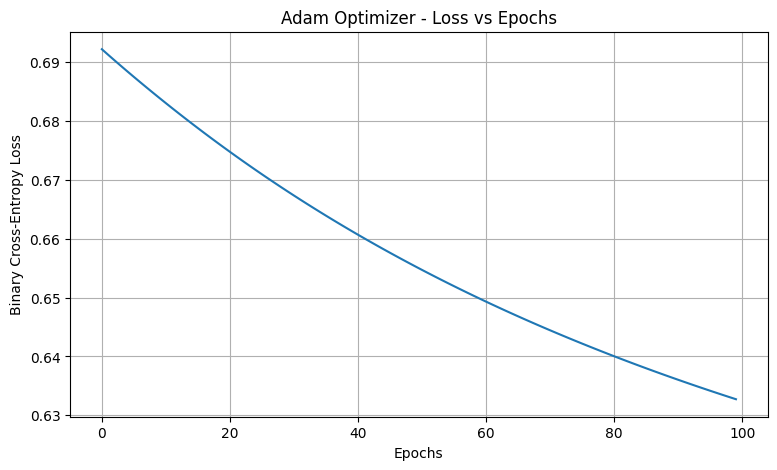

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history_adam)

plt.title("Adam Optimizer - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

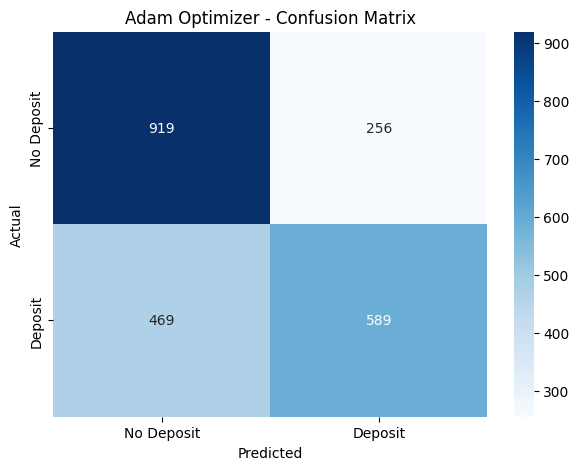

In [9]:
cm_adam = confusion_matrix(y_test, y_pred_adam)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_adam,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.title("Adam Optimizer - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [10]:
print("Adam Optimizer - Classification Report")
print("---------------------------------------")

print(classification_report(
    y_test,
    y_pred_adam,
    target_names=["No Deposit", "Deposit"]
))

Adam Optimizer - Classification Report
---------------------------------------
              precision    recall  f1-score   support

  No Deposit       0.66      0.78      0.72      1175
     Deposit       0.70      0.56      0.62      1058

    accuracy                           0.68      2233
   macro avg       0.68      0.67      0.67      2233
weighted avg       0.68      0.68      0.67      2233



In [11]:
adam_results = {
    "Optimizer": "Adam",
    "Accuracy": accuracy_adam,
    "Precision": precision_adam,
    "Recall": recall_adam,
    "F1-Score": f1_adam,
    "Training Time": training_time_adam,
    "Final Loss": loss_history_adam[-1]
}

print("Adam results saved successfully!")

Adam results saved successfully!
